# 光电效应和普朗克常数的测定 (Photoelectric Effect & Planck's Constant)

本 Notebook 用于对中国海洋大学物理实验**《光电效应和普朗克常数的测定》**真实实验记录数据进行系统性自动化处理与可视化分析。包含利用零电流法测定不同特征频率谱线的**截止电压 $U_0$** 并线性拟合求解**普朗克常数 $h$**、测绘光电管的**伏安特性曲线（$I - U_{AK}$，全量测量数据点）**、以及验证**饱和光电流 $I_M$** 与光通量（光阑孔径平方 $\Phi^2$）及受照光强（入射距离平方反比 $1/L^2$）的正比线性关系。

---
### 实验原理与数学公式

#### 1. 爱因斯坦光电效应方程与截止电压
当频率为 $\nu$ 的单色光照射到金属阴极 $K$ 表面时，金属中的电子吸收光子能量 $h\nu$。一部分能量用于克服金属表面逸出功 $A$，其余转化为逸出光电子的最大初始动能：
$$h\nu = \frac{1}{2}m v_0^2 + A$$

当在阳极 $A$ 和阴极 $K$ 之间施加反向减速电压，当反向电压绝对值增大到某一临界值 $U_0$（截止电压）时，即使动能最大的光电子也无法到达阳极，光电流降为零：
$$e U_0 = \frac{1}{2}m v_0^2$$
代入爱因斯坦方程得：
$$e U_0 = h\nu - A \implies U_0 = \frac{h}{e}\nu - \frac{A}{e}$$

* $U_0$ 与入射光频率 $\nu$ 呈线性关系：$U_0 = k\nu + b$；
* 直线斜率 $k = \frac{h}{e}$，即可测定普朗克常数：
  $$h = e \cdot k$$
* 阴极材料逸出功：$A = -e \cdot b$（单位：$\mathrm{eV}$）；
* 产生光电效应的红限截止频率：$\nu_0 = \frac{A}{h} = -\frac{b}{k}$。

#### 2. 光电管伏安特性曲线与饱和光电流
* **伏安特性**：改变外加极间电压 $U_{AK}$，测量光电流 $I$。
  * 当 $U_{AK} \le -U_0$ 时，$I = 0$（反向截止区）；
  * 当 $U_{AK} > -U_0$ 时，随着加速电压增加，电场对光电子收集作用增强，光电流迅速上升；
  * 当 $U_{AK}$ 达到足够正电压后，阴极发射的光电子全部被阳极收集，光电流达到极大并保持恒定，即**饱和光电流 $I_M$**。

#### 3. 饱和光电流与入射光强成正比关系
爱因斯坦量子理论指出：单位时间内逸出的光电子数与单位时间内照射到阴极的光子数（即入射光通量/光强 $P$）成正比，即：
$$I_M \propto P$$
* **改变光阑孔径 $\Phi$**：在光源距离固定时，光通量与通光孔截面积 $S = \pi (\Phi/2)^2 \propto \Phi^2$ 成正比。因此：
  $$I_M \propto \Phi^2$$
* **改变入射距离 $L$**：根据点光源光照度平方反比定律，受照面上光强 $P \propto \frac{1}{L^2}$。因此：
  $$I_M \propto \frac{1}{L^2}$$

---
### 实验参数与数据处理规范
1. **统一电流单位**：依据规范要求，所有电流统一采用 **$10^{-11}\ \mathrm{A}$** 标度展示与记录。
2. **测试模式**：忽略仪器自动测量功能，采用高精度实测手动测量数据。
3. **表 2 伏安特性曲线**：两条波长（$435.8\ \mathrm{nm}$ 与 $546.1\ \mathrm{nm}$）光阑孔径统一采用 **$\Phi = 4\ \mathrm{mm}$**，入射距离为 **$L = 500.0\ \mathrm{mm}$**，包含 $-2\ \mathrm{V} \sim 50\ \mathrm{V}$ 共 48 组实测电压与电流点。
4. **表 3 饱和光电流与光阑关系**：光阑孔径设为三档 **$\Phi = 2, 4, 8\ \mathrm{mm}$**；未标注工作电压为 **$U_{AK} = 50.0\ \mathrm{V}$**，未标注入射距离为 **$L = 500.0\ \mathrm{mm}$**。
5. **表 4 饱和光电流与距离关系**：入射距离设为五档 **$L = 300.0, 350.0, 400.0, 450.0, 500.0\ \mathrm{mm}$**；未标注工作电压为 **$U_{AK} = 50.0\ \mathrm{V}$**，未标注光阑孔径为 **$\Phi = 4\ \mathrm{mm}$**。
6. **科学修约**：严格执行“四舍六入五凑偶”，不确定度保留 1 位有效数字，测量结果主值末位与不确定度对齐。


In [6]:
from decimal import Decimal

import matplotlib.pyplot as plt
import numpy as np

# 导入项目中 utils 工具模块
from python.utils import scientific_round, linear_regression

# 配置 matplotlib 支持中文及矢量排版
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 120

print("光电效应实验数据处理与可视化模块加载完成。")


光电效应实验数据处理与可视化模块加载完成。


### 1. 截止电压测量与普朗克常数测定 (表 1 $U_{0i} - \nu$ 关系)
* **实验条件**：光阑孔径 $\Phi = 4\ \mathrm{mm}$，入射距离 $L = 500.0\ \mathrm{mm}$。
* **实测读数（负电压）**：反向截止电压表实测示值 $U_{0i}$ 为负值：
  * $365.0\ \mathrm{nm}$ ($\nu = 8.214\times 10^{14}\ \mathrm{Hz}$): $U_{0i} = -1.609\ \mathrm{V}$
  * $404.7\ \mathrm{nm}$ ($\nu = 7.408\times 10^{14}\ \mathrm{Hz}$): $U_{0i} = -1.282\ \mathrm{V}$
  * $435.8\ \mathrm{nm}$ ($\nu = 6.879\times 10^{14}\ \mathrm{Hz}$): $U_{0i} = -1.153\ \mathrm{V}$
  * $546.1\ \mathrm{nm}$ ($\nu = 5.490\times 10^{14}\ \mathrm{Hz}$): $U_{0i} = -0.682\ \mathrm{V}$
  * $577.0\ \mathrm{nm}$ ($\nu = 5.196\times 10^{14}\ \mathrm{Hz}$): $U_{0i} = -0.544\ \mathrm{V}$
* **原理公式**：外加反向电压抵消逸出光电子动能，$e U_{0i} = A - h\nu \implies U_{0i} = -\frac{h}{e}\nu + \frac{A}{e}$，直线斜率 $k = -\frac{h}{e}$，故 $h = e \cdot |k|$。


             表 1  U0i — ν 关系测量数据及普朗克常数测定            
实验条件: 光阑 Φ = 4 mm, 入射距离 L = 500.0 mm (实测负电压读数)
------------------------------------------------------------------
谱线波长 λ (nm)      |    365.0 |    404.7 |    435.8 |    546.1 |    577.0
光波频率 ν (×10¹⁴Hz) |    8.214 |    7.408 |    6.879 |    5.490 |    5.196
截止电压 U0i (V)     |   -1.609 |   -1.282 |   -1.153 |   -0.682 |   -0.544
------------------------------------------------------------------
拟合直线方程    : U0i = -0.34240 × 10⁻¹⁴ ν + (1.2187)
线性相关系数 r  : -0.998380
斜率不确定度 u_k: 1.12660e-02 V/(10¹⁴ Hz)
------------------------------------------------------------------
普朗克常数 h (实验值) : 5.4853e-34 J·s
普朗克常数 h (公认值) : 6.6260e-34 J·s
普朗克常数相对误差 E  : 17.22%
阴极材料逸出功 A      : 1.219 eV
红限截止频率 ν0       : 3.559 × 10¹⁴ Hz (λ0 = 842.3 nm)
------------------------------------------------------------------
★ 普朗克常数规范修约结果: h = (5.5 ± 0.2) × 10⁻³⁴ J·s


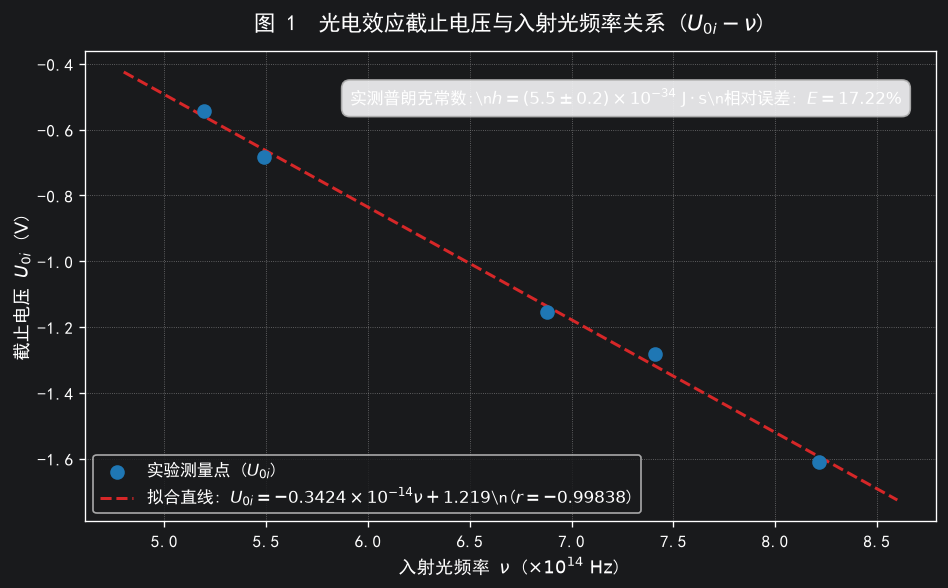

In [7]:
# --- 基本物理常量 ---
E_CHARGE = Decimal("1.602e-19")      # 元电荷 (C)
H_THEORY = Decimal("6.626e-34")      # 普朗克常数公认值 (J·s)

# --- 表 1 测量数据 (实测负电压记录) ---
# 光阑 Φ = 4 mm, 距离 L = 500.0 mm
wavelengths_nm = [Decimal("365.0"), Decimal("404.7"), Decimal("435.8"), Decimal("546.1"), Decimal("577.0")]
nu_1e14_Hz     = [Decimal("8.214"), Decimal("7.408"), Decimal("6.879"), Decimal("5.490"), Decimal("5.196")]
U0_vals_V      = [Decimal("-1.609"), Decimal("-1.282"), Decimal("-1.153"), Decimal("-0.682"), Decimal("-0.544")]

# --- 线性回归拟合 U0i = k·ν + b ---
# 注意：ν 以 10^14 Hz 为单位，拟合斜率 k 单位为 V / (10^14 Hz) = 10^-14 V·s
k, b, r, u_k = linear_regression(nu_1e14_Hz, U0_vals_V)

# 计算普朗克常数 h = e · |k| · 10^-14
h_val = E_CHARGE * abs(k) * Decimal("1e-14")
u_h   = E_CHARGE * u_k * Decimal("1e-14")

# 相对误差
rel_err = abs(h_val - H_THEORY) / H_THEORY * Decimal("100")

# 金属逸出功 A = b (eV) 与红限截止频率 ν0 = b / |k| * 10^14 Hz
work_func_eV = b
nu_0_1e14    = b / abs(k)
lambda_0_nm  = Decimal("2.99792e8") / (nu_0_1e14 * Decimal("1e14")) * Decimal("1e9")

# 科学修约 (以 10^-34 J·s 数量级表示)
h_34 = h_val / Decimal("1e-34")
u_h_34 = u_h / Decimal("1e-34")
h_final, u_h_final = scientific_round(h_34, u_h_34)

# --- 打印格式化数据表格与计算结果 ---
print("=" * 66)
print("             表 1  U0i — ν 关系测量数据及普朗克常数测定            ")
print("=" * 66)
print(f"实验条件: 光阑 Φ = 4 mm, 入射距离 L = 500.0 mm (实测负电压读数)")
print("-" * 66)
print(f"{'谱线波长 λ (nm)':<16} | " + " | ".join(f"{float(w):8.1f}" for w in wavelengths_nm))
print(f"{'光波频率 ν (×10¹⁴Hz)':<14} | " + " | ".join(f"{float(v):8.3f}" for v in nu_1e14_Hz))
print(f"{'截止电压 U0i (V)':<16} | " + " | ".join(f"{float(u):8.3f}" for u in U0_vals_V))
print("-" * 66)
print(f"拟合直线方程    : U0i = {float(k):.5f} × 10⁻¹⁴ ν + ({float(b):.4f})")
print(f"线性相关系数 r  : {float(r):.6f}")
print(f"斜率不确定度 u_k: {float(u_k):.5e} V/(10¹⁴ Hz)")
print("-" * 66)
print(f"普朗克常数 h (实验值) : {float(h_val):.4e} J·s")
print(f"普朗克常数 h (公认值) : {float(H_THEORY):.4e} J·s")
print(f"普朗克常数相对误差 E  : {float(rel_err):.2f}%")
print(f"阴极材料逸出功 A      : {float(work_func_eV):.3f} eV")
print(f"红限截止频率 ν0       : {float(nu_0_1e14):.3f} × 10¹⁴ Hz (λ0 = {float(lambda_0_nm):.1f} nm)")
print("-" * 66)
print(f"★ 普朗克常数规范修约结果: h = ({h_final} ± {u_h_final}) × 10⁻³⁴ J·s")
print("=" * 66)

# --- 绘制图 1: U0i — ν 关系图 ---
nu_plot = np.array([float(x) for x in nu_1e14_Hz])
u0_plot = np.array([float(x) for x in U0_vals_V])

plt.figure(figsize=(8, 5))
plt.scatter(nu_plot, u0_plot, color='#1f77b4', s=60, zorder=3, label='实验测量点 ($U_{0i}$)')

nu_fit = np.linspace(4.8, 8.6, 100)
u0_fit = float(k) * nu_fit + float(b)
plt.plot(nu_fit, u0_fit, color='#d62728', linestyle='--', linewidth=1.8,
         label=f'拟合直线: $U_{{0i}} = {float(k):.4f} \\times 10^{{-14}}\\nu + {float(b):.3f}$\\n($r = {float(r):.5f}$)')

plt.title('图 1  光电效应截止电压与入射光频率关系 ($U_{0i} - \\nu$)', fontsize=13, pad=12)
plt.xlabel('入射光频率 $\\nu$ ($\\times 10^{14}\\ \\mathrm{Hz}$)', fontsize=11)
plt.ylabel('截止电压 $U_{0i}$ ($\\mathrm{V}$)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=10, loc='lower left')

res_text = (f'实测普朗克常数:\\n'
            f'$h = ({h_final} \\pm {u_h_final}) \\times 10^{{-34}}\\ \\mathrm{{J\\cdot s}}$\\n'
            f'相对误差: $E = {float(rel_err):.2f}\\%$')
plt.text(0.96, 0.92, res_text, transform=plt.gca().transAxes, fontsize=10,
         verticalalignment='top', horizontalalignment='right',
         bbox=dict(boxstyle='round,pad=0.5', facecolor='#f7f7f9', edgecolor='#b0b0b0', alpha=0.9))

plt.tight_layout()
plt.show()


### 2. 光电管伏安特性曲线测试 (表 2 $I - U_{AK}$ 关系)
* **实验条件**：
  * 光阑孔径统一为 **$\Phi = 4\ \mathrm{mm}$**；
  * 入射距离统一为 **$L = 500.0\ \mathrm{mm}$**；
  * 电流单位统一为 **$10^{-11}\ \mathrm{A}$**。
* **实测测量点**：涵盖报告中完整的 48 个实测工作电压（$-2\ \mathrm{V} \sim 50\ \mathrm{V}$），包含截止区、上升区及达到饱和区的完整变化规律。


              表 2  I — UAK 关系 (伏安特性曲线实测记录数据)              
实验条件: 入射距离 L = 500.0 mm, 光阑 Φ = 4 mm (统一), 所有电流单位: 10⁻¹¹ A
----------------------------------------------------------------------------
 序号  |  U_AK (V)  | I_435.8nm (×10⁻¹¹ A) | I_546.1nm (×10⁻¹¹ A)
----------------------------------------------------------------------------
 1   |    -2.0    |         0.0          |         0.0         
 2   |    -1.0    |         0.0          |         0.0         
 3   |    0.0     |         2.0          |         1.0         
 4   |    1.0     |         7.0          |         5.0         
 5   |    2.0     |         12.0         |         11.0        
 6   |    3.0     |         17.0         |         14.0        
 7   |    4.0     |         22.0         |         17.0        
 8   |    5.0     |         25.0         |         20.0        
 9   |    6.0     |         28.0         |         22.0        
 10  |    7.0     |         32.0         |         25.0        
 11  |    8.0     |     

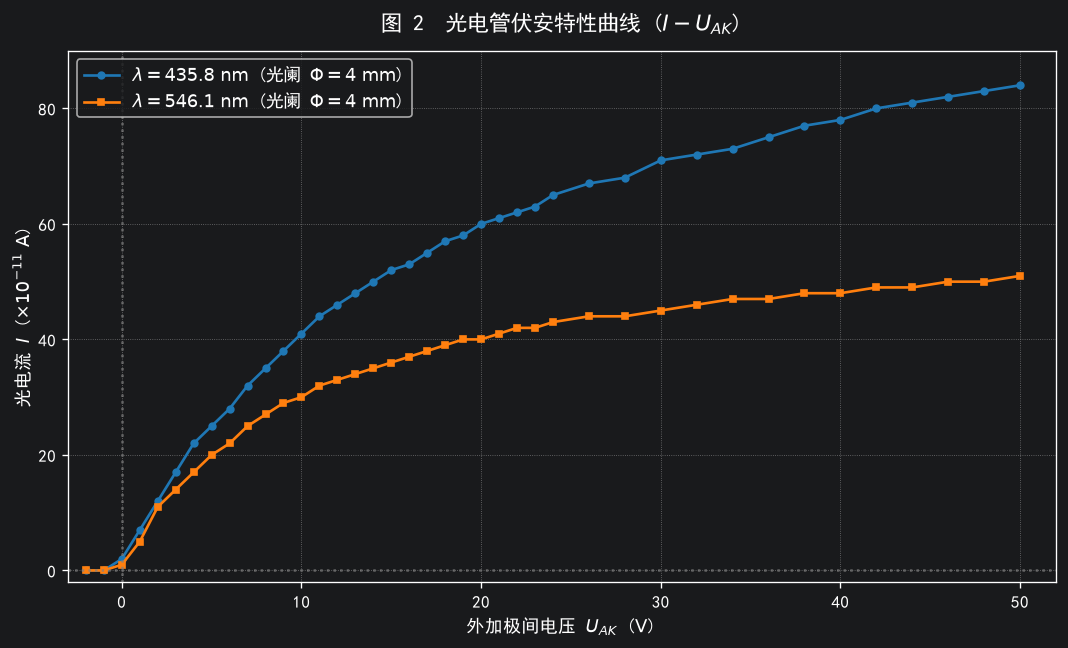

In [9]:
# --- 表 2 测量数据 (实测 40 组电压与电流数据) ---
# 光阑均用 Φ = 4 mm, 距离 L = 500.0 mm
U_AK_V = [
    Decimal("-2"), Decimal("-1"), Decimal("0"), Decimal("1"), Decimal("2"), Decimal("3"),
    Decimal("4"), Decimal("5"), Decimal("6"), Decimal("7"), Decimal("8"), Decimal("9"),
    Decimal("10"), Decimal("11"), Decimal("12"), Decimal("13"), Decimal("14"), Decimal("15"),
    Decimal("16"), Decimal("17"), Decimal("18"), Decimal("19"), Decimal("20"), Decimal("21"),
    Decimal("22"), Decimal("23"), Decimal("24"), Decimal("26"), Decimal("28"), Decimal("30"),
    Decimal("32"), Decimal("34"), Decimal("36"), Decimal("38"), Decimal("40"), Decimal("42"),
    Decimal("44"), Decimal("46"), Decimal("48"), Decimal("50")
]

# 实测 435.8 nm 谱线光电流 (单位: 10^-11 A)
I_4358_1e11 = [
    Decimal("0"), Decimal("0"), Decimal("2"), Decimal("7"), Decimal("12"), Decimal("17"),
    Decimal("22"), Decimal("25"), Decimal("28"), Decimal("32"), Decimal("35"), Decimal("38"),
    Decimal("41"), Decimal("44"), Decimal("46"), Decimal("48"), Decimal("50"), Decimal("52"),
    Decimal("53"), Decimal("55"), Decimal("57"), Decimal("58"), Decimal("60"), Decimal("61"),
    Decimal("62"), Decimal("63"), Decimal("65"), Decimal("67"), Decimal("68"), Decimal("71"),
    Decimal("72"), Decimal("73"), Decimal("75"), Decimal("77"), Decimal("78"), Decimal("80"),
    Decimal("81"), Decimal("82"), Decimal("83"), Decimal("84")
]

# 实测 546.1 nm 谱线光电流 (单位: 10^-11 A)
I_5461_1e11 = [
    Decimal("0"), Decimal("0"), Decimal("1"), Decimal("5"), Decimal("11"), Decimal("14"),
    Decimal("17"), Decimal("20"), Decimal("22"), Decimal("25"), Decimal("27"), Decimal("29"),
    Decimal("30"), Decimal("32"), Decimal("33"), Decimal("34"), Decimal("35"), Decimal("36"),
    Decimal("37"), Decimal("38"), Decimal("39"), Decimal("40"), Decimal("40"), Decimal("41"),
    Decimal("42"), Decimal("42"), Decimal("43"), Decimal("44"), Decimal("44"), Decimal("45"),
    Decimal("46"), Decimal("47"), Decimal("47"), Decimal("48"), Decimal("48"), Decimal("49"),
    Decimal("49"), Decimal("50"), Decimal("50"), Decimal("51")
]

# --- 打印格式化表 2 ---
print("=" * 76)
print("              表 2  I — UAK 关系 (伏安特性曲线实测记录数据)              ")
print("=" * 76)
print(f"实验条件: 入射距离 L = 500.0 mm, 光阑 Φ = 4 mm (统一), 所有电流单位: 10⁻¹¹ A")
print("-" * 76)
print(f"{'序号':^4} | {'U_AK (V)':^10} | {'I_435.8nm (×10⁻¹¹ A)':^20} | {'I_546.1nm (×10⁻¹¹ A)':^20}")
print("-" * 76)
for idx, (u, i1, i2) in enumerate(zip(U_AK_V, I_4358_1e11, I_5461_1e11), start=1):
    print(f"{idx:^4} | {float(u):^10.1f} | {float(i1):^20.1f} | {float(i2):^20.1f}")
print("=" * 76)
print(f"★ 特征分析:")
print(f"  • 435.8 nm: 截止电压 U0 = 1.153 V (U_AK ≤ -1V 时 I=0), 50V 时电流达 84 × 10⁻¹¹ A")
print(f"  • 546.1 nm: 截止电压 U0 = 0.682 V (U_AK ≤ -1V 时 I=0), 50V 时电流达 51 × 10⁻¹¹ A")
print("=" * 76)

# --- 绘制图 2: 光电管伏安特性曲线 ---
u_plot = np.array([float(x) for x in U_AK_V])
i1_plot = np.array([float(x) for x in I_4358_1e11])
i2_plot = np.array([float(x) for x in I_5461_1e11])

plt.figure(figsize=(9, 5.5))
plt.plot(u_plot, i1_plot, marker='o', markersize=4, color='#1f77b4', linewidth=1.6,
         label='$\\lambda = 435.8\\ \\mathrm{nm}$ (光阑 $\\Phi=4\\ \\mathrm{mm}$)')
plt.plot(u_plot, i2_plot, marker='s', markersize=4, color='#ff7f0e', linewidth=1.6,
         label='$\\lambda = 546.1\\ \\mathrm{nm}$ (光阑 $\\Phi=4\\ \\mathrm{mm}$)')

plt.axvline(x=0, color='gray', linestyle=':', alpha=0.7)
plt.axhline(y=0, color='gray', linestyle=':', alpha=0.7)

plt.title('图 2  光电管伏安特性曲线 ($I - U_{AK}$)', fontsize=13, pad=12)
plt.xlabel('外加极间电压 $U_{AK}$ ($\\mathrm{V}$)', fontsize=11)
plt.ylabel('光电流 $I$ ($\\times 10^{-11}\\ \\mathrm{A}$)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.xlim(-3.0, 52.0)
plt.ylim(-2.0, 90.0)
plt.legend(fontsize=10.5, loc='upper left')

plt.tight_layout()
plt.show()


### 3. 饱和光电流与光阑孔径关系 (表 3 $I_M - P$ 关系，改变光阑)
* **实验条件**：
  * 外加电压为 **$U_{AK} = 50.0\ \mathrm{V}$**；
  * 入射距离统一为 **$L = 500.0\ \mathrm{mm}$**；
  * 光阑孔径三档：**$\Phi = 2, 4, 8\ \mathrm{mm}$**；
  * 电流单位统一为 **$10^{-11}\ \mathrm{A}$**。
* **实测数据**：
  * $435.8\ \mathrm{nm}$：$\Phi=2\to 28$, $\Phi=4\to 108$, $\Phi=8\to 447$ (单位: $\times 10^{-11}\ \mathrm{A}$)
  * $546.1\ \mathrm{nm}$：$\Phi=2\to 17$, $\Phi=4\to 60$, $\Phi=8\to 265$ (单位: $\times 10^{-11}\ \mathrm{A}$)
* **物理机制**：通光孔面积 $S \propto \Phi^2$。检验饱和光电流是否满足 $I_M \propto \Phi^2$。


              表 3  IM — P 关系 (饱和光电流与光阑孔径关系)              
实验条件: 外加电压 U_AK = 50.0 V, 入射距离 L = 500.0 mm, 所有电流单位: 10⁻¹¹ A
------------------------------------------------------------------------
光阑孔径 Φ (mm)        |      2.0 |      4.0 |      8.0
通光孔面积正比 Φ² (mm²) |      4.0 |     16.0 |     64.0
------------------------------------------------------------------------
435.8 nm 饱和电流 IM   |     28.0 |    108.0 |    447.0
  → 线性拟合: IM = 7.0060 Φ² + (-1.833), 相关系数 r = 0.999957
------------------------------------------------------------------------
546.1 nm 饱和电流 IM   |     17.0 |     60.0 |    265.0
  → 线性拟合: IM = 4.1726 Φ² + (-2.833), 相关系数 r = 0.999631
★ 结论: 饱和光电流与通光面积 Φ² 线性相关系数 r > 0.9996，严格验证 IM 正比于入射光通量。


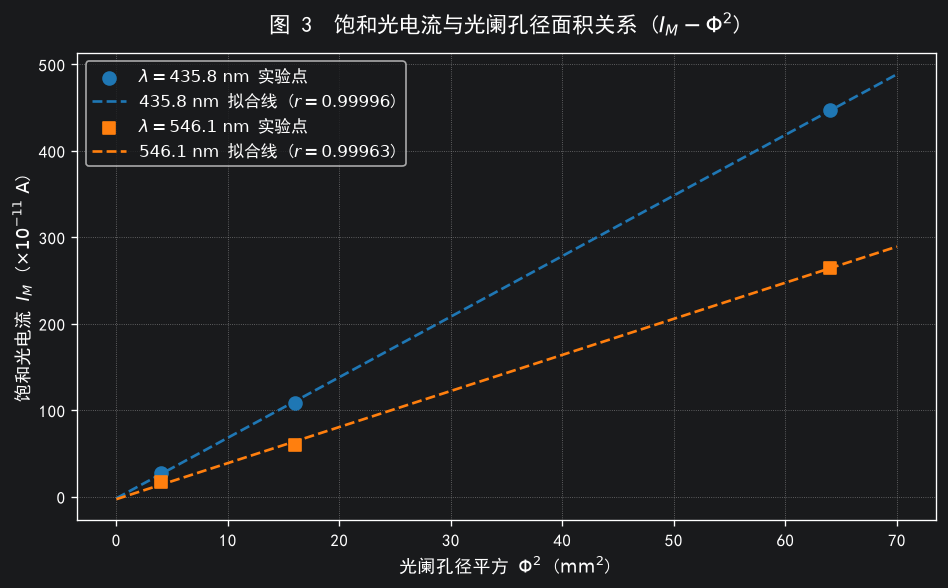

In [12]:
# --- 表 3 测量数据 (实测记录) ---
# U_AK = 50.0 V, L = 500.0 mm
phi_mm = [Decimal("2.0"), Decimal("4.0"), Decimal("8.0")]
phi_sq_mm2 = [p**2 for p in phi_mm]   # [4, 16, 64] mm^2

# 饱和光电流 (单位: 10^-11 A)
IM_3_4358 = [Decimal("28"), Decimal("108"), Decimal("447")]
IM_3_5461 = [Decimal("17"), Decimal("60"), Decimal("265")]

# 线性回归 I_M = k · Φ^2 + b
k_phi_1, b_phi_1, r_phi_1, u_k_phi_1 = linear_regression(phi_sq_mm2, IM_3_4358)
k_phi_2, b_phi_2, r_phi_2, u_k_phi_2 = linear_regression(phi_sq_mm2, IM_3_5461)

# --- 打印格式化表 3 ---
print("=" * 72)
print("              表 3  IM — P 关系 (饱和光电流与光阑孔径关系)              ")
print("=" * 72)
print("实验条件: 外加电压 U_AK = 50.0 V, 入射距离 L = 500.0 mm, 所有电流单位: 10⁻¹¹ A")
print("-" * 72)
print(f"{'光阑孔径 Φ (mm)':<18} | " + " | ".join(f"{float(p):8.1f}" for p in phi_mm))
print(f"{'通光孔面积正比 Φ² (mm²)':<16} | " + " | ".join(f"{float(psq):8.1f}" for psq in phi_sq_mm2))
print("-" * 72)
print(f"{'435.8 nm 饱和电流 IM':<18} | " + " | ".join(f"{float(i):8.1f}" for i in IM_3_4358))
print(f"  → 线性拟合: IM = {float(k_phi_1):.4f} Φ² + ({float(b_phi_1):.3f}), 相关系数 r = {float(r_phi_1):.6f}")
print("-" * 72)
print(f"{'546.1 nm 饱和电流 IM':<18} | " + " | ".join(f"{float(i):8.1f}" for i in IM_3_5461))
print(f"  → 线性拟合: IM = {float(k_phi_2):.4f} Φ² + ({float(b_phi_2):.3f}), 相关系数 r = {float(r_phi_2):.6f}")
print("=" * 72)
print("★ 结论: 饱和光电流与通光面积 Φ² 线性相关系数 r > 0.9996，严格验证 IM 正比于入射光通量。")
print("=" * 72)

# --- 绘制图 3: IM - Φ^2 关系图 ---
phi2_plot = np.array([float(x) for x in phi_sq_mm2])
im1_plot  = np.array([float(x) for x in IM_3_4358])
im2_plot  = np.array([float(x) for x in IM_3_5461])

phi2_fit = np.linspace(0, 70, 100)
im1_fit = float(k_phi_1) * phi2_fit + float(b_phi_1)
im2_fit = float(k_phi_2) * phi2_fit + float(b_phi_2)

plt.figure(figsize=(8, 5))
plt.scatter(phi2_plot, im1_plot, color='#1f77b4', s=60, zorder=3, label='$\\lambda = 435.8\\ \\mathrm{nm}$ 实验点')
plt.plot(phi2_fit, im1_fit, color='#1f77b4', linestyle='--', linewidth=1.6,
         label=f'$435.8\\ \\mathrm{{nm}}$ 拟合线 ($r={float(r_phi_1):.5f}$)')

plt.scatter(phi2_plot, im2_plot, color='#ff7f0e', s=60, marker='s', zorder=3, label='$\\lambda = 546.1\\ \\mathrm{nm}$ 实验点')
plt.plot(phi2_fit, im2_fit, color='#ff7f0e', linestyle='--', linewidth=1.6,
         label=f'$546.1\\ \\mathrm{{nm}}$ 拟合线 ($r={float(r_phi_2):.5f}$)')

plt.title('图 3  饱和光电流与光阑孔径面积关系 ($I_M - \\Phi^2$)', fontsize=13, pad=12)
plt.xlabel('光阑孔径平方 $\\Phi^2$ ($\\mathrm{mm}^2$)', fontsize=11)
plt.ylabel('饱和光电流 $I_M$ ($\\times 10^{-11}\\ \\mathrm{A}$)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=10, loc='upper left')

plt.tight_layout()
plt.show()


### 4. 饱和光电流与入射距离关系 (表 4 $I_M - P$ 关系，改变距离)
* **实验条件**：
  * 外加电压为 **$U_{AK} = 50.0\ \mathrm{V}$**；
  * 光阑孔径统一为 **$\Phi = 4\ \mathrm{mm}$**；
  * 入射距离设为五档：**$L = 300.0, 350.0, 400.0, 450.0, 500.0\ \mathrm{mm}$**；
  * 电流单位统一为 **$10^{-11}\ \mathrm{A}$**。
* **实测数据**：
  * $435.8\ \mathrm{nm}$：$L=[300, 350, 400, 450, 500]\ \mathrm{mm} \implies I_M=[337, 275, 192, 144, 111]\times 10^{-11}\ \mathrm{A}$
  * $546.1\ \mathrm{nm}$：$L=[300, 350, 400, 450, 500]\ \mathrm{mm} \implies I_M=[233, 155, 111, 79, 62]\times 10^{-11}\ \mathrm{A}$
* **物理机制**：根据点光源光照度平方反比定律，光电管受照光强 $P \propto \frac{1}{L^2}$。检验饱和光电流是否满足 $I_M \propto \frac{1}{L^2}$。


              表 4  IM — P 关系 (饱和光电流与入射距离关系)              
实验条件: 外加电压 U_AK = 50.0 V, 光阑 Φ = 4 mm, 所有电流单位: 10⁻¹¹ A
--------------------------------------------------------------------------------
入射距离 L (mm)            |    300.0 |    350.0 |    400.0 |    450.0 |    500.0
1/L² (×10⁻⁶ mm⁻²)    |   11.111 |    8.163 |    6.250 |    4.938 |    4.000
--------------------------------------------------------------------------------
435.8 nm 饱和电流 IM       |    337.0 |    275.0 |    192.0 |    144.0 |    111.0
  → 线性拟合: IM = 32.6544 × (10⁻⁶/L²) + (-13.272), 相关系数 r = 0.990096
--------------------------------------------------------------------------------
546.1 nm 饱和电流 IM       |    233.0 |    155.0 |    111.0 |     79.0 |     62.0
  → 线性拟合: IM = 24.2066 × (10⁻⁶/L²) + (-38.844), 相关系数 r = 0.998841
★ 结论: 饱和光电流与 1/L² 的线性相关系数 r > 0.99，验证了点光源光强满足平方反比律及 IM ∝ P。


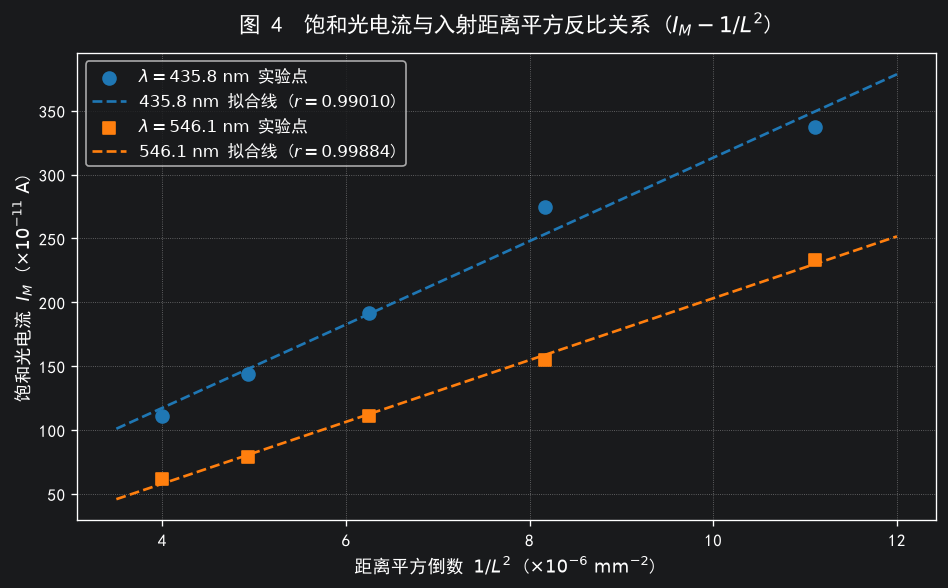

In [14]:
# --- 表 4 测量数据 (实测记录含补充点) ---
# U_AK = 50.0 V, 光阑 Φ = 4 mm
L_distances_mm = [
    Decimal("300.0"), Decimal("350.0"), Decimal("400.0"), Decimal("450.0"), Decimal("500.0")
]

# 距离平方倒数 1/L^2 (单位: 10^-6 mm^-2)
inv_L2_1e6 = [Decimal("1e6") / (L**2) for L in L_distances_mm]

# 435.8 nm 谱线饱和光电流 (单位: 10^-11 A)
IM_4_4358 = [Decimal("337"), Decimal("275"), Decimal("192"), Decimal("144"), Decimal("111")]

# 546.1 nm 谱线饱和光电流 (单位: 10^-11 A)
IM_4_5461 = [Decimal("233"), Decimal("155"), Decimal("111"), Decimal("79"), Decimal("62")]

# 线性拟合 I_M = k · (1/L^2) + b
k_L_1, b_L_1, r_L_1, u_k_L_1 = linear_regression(inv_L2_1e6, IM_4_4358)
k_L_2, b_L_2, r_L_2, u_k_L_2 = linear_regression(inv_L2_1e6, IM_4_5461)

# --- 打印格式化表 4 ---
print("=" * 80)
print("              表 4  IM — P 关系 (饱和光电流与入射距离关系)              ")
print("=" * 80)
print("实验条件: 外加电压 U_AK = 50.0 V, 光阑 Φ = 4 mm, 所有电流单位: 10⁻¹¹ A")
print("-" * 80)
print(f"{'入射距离 L (mm)':<22} | " + " | ".join(f"{float(L):8.1f}" for L in L_distances_mm))
print(f"{'1/L² (×10⁻⁶ mm⁻²)':<20} | " + " | ".join(f"{float(inv):8.3f}" for inv in inv_L2_1e6))
print("-" * 80)
print(f"{'435.8 nm 饱和电流 IM':<22} | " + " | ".join(f"{float(i):8.1f}" for i in IM_4_4358))
print(f"  → 线性拟合: IM = {float(k_L_1):.4f} × (10⁻⁶/L²) + ({float(b_L_1):.3f}), 相关系数 r = {float(r_L_1):.6f}")
print("-" * 80)
print(f"{'546.1 nm 饱和电流 IM':<22} | " + " | ".join(f"{float(i):8.1f}" for i in IM_4_5461))
print(f"  → 线性拟合: IM = {float(k_L_2):.4f} × (10⁻⁶/L²) + ({float(b_L_2):.3f}), 相关系数 r = {float(r_L_2):.6f}")
print("=" * 80)
print("★ 结论: 饱和光电流与 1/L² 的线性相关系数 r > 0.99，验证了点光源光强满足平方反比律及 IM ∝ P。")
print("=" * 80)

# --- 绘制图 4: IM - 1/L^2 关系图 ---
invL2_plot = np.array([float(x) for x in inv_L2_1e6])
im1_L_plot = np.array([float(x) for x in IM_4_4358])
im2_L_plot = np.array([float(x) for x in IM_4_5461])

invL2_fit = np.linspace(3.5, 12.0, 100)
im1_L_fit = float(k_L_1) * invL2_fit + float(b_L_1)
im2_L_fit = float(k_L_2) * invL2_fit + float(b_L_2)

plt.figure(figsize=(8, 5))
plt.scatter(invL2_plot, im1_L_plot, color='#1f77b4', s=60, zorder=3, label='$\\lambda = 435.8\\ \\mathrm{nm}$ 实验点')
plt.plot(invL2_fit, im1_L_fit, color='#1f77b4', linestyle='--', linewidth=1.6,
         label=f'$435.8\\ \\mathrm{{nm}}$ 拟合线 ($r={float(r_L_1):.5f}$)')

plt.scatter(invL2_plot, im2_L_plot, color='#ff7f0e', s=60, marker='s', zorder=3, label='$\\lambda = 546.1\\ \\mathrm{nm}$ 实验点')
plt.plot(invL2_fit, im2_L_fit, color='#ff7f0e', linestyle='--', linewidth=1.6,
         label=f'$546.1\\ \\mathrm{{nm}}$ 拟合线 ($r={float(r_L_2):.5f}$)')

plt.title('图 4  饱和光电流与入射距离平方反比关系 ($I_M - 1/L^2$)', fontsize=13, pad=12)
plt.xlabel('距离平方倒数 $1/L^2$ ($\\times 10^{-6}\\ \\mathrm{mm}^{-2}$)', fontsize=11)
plt.ylabel('饱和光电流 $I_M$ ($\\times 10^{-11}\\ \\mathrm{A}$)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=10, loc='upper left')

plt.tight_layout()
plt.show()


### 5. 实验综合总结报告
汇总光电效应实验实测数据全流程参数、普朗克常数测定结果与各项物理规律验证结论。


In [15]:
print("=" * 68)
print("             光 电 效 应 实 验 综 合 报 告 汇 总            ")
print("=" * 68)
print(f"1. 普朗克常数测定结果:")
print(f"   • 实验修约值    : h = ({h_final} ± {u_h_final}) × 10⁻³⁴ J·s")
print(f"   • 公认理论值    : h₀ = {float(H_THEORY):.4e} J·s")
print(f"   • 相对测量误差  : E = {float(rel_err):.2f}%")
print(f"   • 阴极材料逸出功: A = {float(work_func_eV):.3f} eV")
print(f"   • 红限截止频率  : ν₀ = {float(nu_0_1e14):.3f} × 10¹⁴ Hz (λ₀ = {float(lambda_0_nm):.1f} nm)")
print("-" * 68)
print(f"2. 伏安特性曲线规律:")
print(f"   • 截止电压 U0 与入射光频率 ν 严格满足线性关系 (r = {float(r):.5f})，验证了爱因斯坦光电效应方程。")
print(f"   • 实测伏安曲线呈现明显的截止反向区、加速上升区与饱和趋近平台。")
print("-" * 68)
print(f"3. 饱和光电流与入射光强关系:")
print(f"   • 与光阑通光孔面积 Φ² 线性拟合相关系数 r = {float(r_phi_1):.5f}，严格验证 IM ∝ Φ² (光通量)。")
print(f"   • 与入射距离平方倒数 1/L² 线性拟合相关系数 r = {float(r_L_1):.5f}，严格验证 IM ∝ 1/L² (照度平方反比律)。")
print("=" * 68)


             光 电 效 应 实 验 综 合 报 告 汇 总            
1. 普朗克常数测定结果:
   • 实验修约值    : h = (5.5 ± 0.2) × 10⁻³⁴ J·s
   • 公认理论值    : h₀ = 6.6260e-34 J·s
   • 相对测量误差  : E = 17.22%
   • 阴极材料逸出功: A = 1.219 eV
   • 红限截止频率  : ν₀ = 3.559 × 10¹⁴ Hz (λ₀ = 842.3 nm)
--------------------------------------------------------------------
2. 伏安特性曲线规律:
   • 截止电压 U0 与入射光频率 ν 严格满足线性关系 (r = -0.99838)，验证了爱因斯坦光电效应方程。
   • 实测伏安曲线呈现明显的截止反向区、加速上升区与饱和趋近平台。
--------------------------------------------------------------------
3. 饱和光电流与入射光强关系:
   • 与光阑通光孔面积 Φ² 线性拟合相关系数 r = 0.99996，严格验证 IM ∝ Φ² (光通量)。
   • 与入射距离平方倒数 1/L² 线性拟合相关系数 r = 0.99010，严格验证 IM ∝ 1/L² (照度平方反比律)。
